# Projecte: BICITIERRA - Neteja de dades de sales history

In [1]:
# En primer lloc anem a carregar les llibreries necessàries i llegir el dataset de vendes.
import pandas as pd

# tin en compte que la ruta el dataset por variar en funció de com tingues organitzada la carpeta del projecte
df = pd.read_csv('./dades/sales_history.csv')
#3. Després mostre les 15 primeres línies.
df.head(15)

,month,channel,product_line,region,marketing_spend,avg_discount,stock_units,website_sessions,sales_units,revenue,marketing_budget,planned_discount,list_price,campaign,days_in_month,closing_stock_units,stockout
0,2021-01,store,urban,coast,2190.14,0.047,150,3763.0,95,38024.70,2002.85,0.034,420.0,none,31,55,0
1,2021-01,store,urban,inland,3281.92,0.074,88,4664.0,82,31891.44,3016.71,0.062,420.0,none,31,6,0
2,2021-01,store,urban,metro,3347.16,0.050,141,5073.0,141,56259.00,3386.79,0.046,420.0,none,31,0,1
3,2021-01,store,mountain,coast,2530.35,0.037,66,3705.0,56,37210.32,2396.99,0.028,690.0,none,31,10,0
4,2021-01,store,mountain,inland,2136.16,0.101,61,3318.0,44,27293.64,2272.67,0.092,690.0,none,31,17,0
5,2021-01,store,mountain,metro,3566.49,0.011,48,4541.0,48,32755.68,3308.59,0.012,690.0,none,31,0,1
6,2021-01,store,electric,coast,1706.78,0.075,57,2693.0,39,53391.00,1811.32,0.071,1480.0,none,31,18,0
7,2021-01,store,electric,inland,3840.56,0.056,17,4483.0,17,23751.04,3652.61,0.047,1480.0,none,31,0,1
8,2021-01,store,electric,metro,2578.57,0.023,55,3765.0,48,69406.08,2722.88,0.043,1480.0,none,31,7,0
9,2021-01,ecommerce,urban,coast,3067.64,0.045,189,7085.0,130,52143.00,3138.31,0.046,420.0,none,31,59,0


### Pas 1: Descarregar les dades i construir el DataFrame

In [2]:
# Mostrem l'estructura del DataFrame (noms de les columnes i tipus de dades)
print("Shape:", df.shape) # Mostra la quantitat de files i columnes
print("\nColumns and data types:") # Mostra els noms de les columnes i els tipus de dades
print(df.dtypes)


Shape: (1188, 17)

Columns and data types:
month                      str
channel                    str
product_line               str
region                     str
marketing_spend        float64
avg_discount           float64
stock_units              int64
website_sessions       float64
sales_units              int64
revenue                float64
marketing_budget       float64
planned_discount       float64
list_price             float64
campaign                   str
days_in_month            int64
closing_stock_units      int64
stockout                 int64
dtype: object


### Pas 2: Preprocessament de les dades

Abans de començar a entrenar els models, és important fer un preprocessament de les dades. 

- Comproveu si hi ha valors nuls i, si n'hi ha, decidiu com tractar-los (per exemple, eliminant les files amb valors nuls o omplint-los amb la mitjana o la mediana)
- Comproveu si hi ha variables categòriques (no numèriques). Decidiu què fer amb elles.
- Mireu si hi ha molta diferència entre les magnituds de les diferents característiques i decidiu si seria convenient normalitzar o estandarditzar algunes d'elles.

In [3]:
# Comprovem si hi ha valors nuls al DataFrame
print("\nNull values in each column:")
print(df.isnull().sum())


Null values in each column:
month                   0
channel                 0
product_line            0
region                  0
marketing_spend        18
avg_discount           24
stock_units             0
website_sessions       18
sales_units             0
revenue                 0
marketing_budget       12
planned_discount       12
list_price              0
campaign                0
days_in_month           0
closing_stock_units     0
stockout                0
dtype: int64


In [4]:
# Tractem els nulls
cols = ["marketing_spend", "avg_discount", "website_sessions",
        "marketing_budget", "planned_discount"]

# Mira abans la distribució
print(df[cols].describe())

# En average_discount i planned_discount hi ha valors que són 0.00, per tant anem a asumir que en estes columnes el nul equival a 0.
# Pel que fa a la resta de columnes considerem que sí podriem sustituir els nuls per la mediana.

# La mitjana és la suma de tots els valors dividida pel nombre de valors. 
# La mediana és el valor que queda al mig quan ordenes les dades de menor a major.

       marketing_spend  avg_discount  website_sessions  marketing_budget  \
count      1170.000000   1164.000000       1170.000000       1176.000000   
mean       2851.213812      0.076083       5466.698291       2863.435748   
std        1084.577937      0.045830       1568.814205       1072.068280   
min         920.680000      0.000000       2120.000000       1014.670000   
25%        1999.882500      0.045000       4158.000000       1985.257500   
50%        2831.765000      0.063000       5506.500000       2833.150000   
75%        3601.235000      0.097250       6655.750000       3648.410000   
max        6059.990000      0.219000      10261.000000       5664.070000   

       planned_discount  
count       1176.000000  
mean           0.076283  
std            0.044783  
min            0.000000  
25%            0.045000  
50%            0.063000  
75%            0.096250  
max            0.206000  


In [5]:
# Descomptes: nul = sense descompte
df[["avg_discount", "planned_discount"]] = df[["avg_discount", "planned_discount"]].fillna(0)

# Resta: mediana
for c in ["marketing_spend", "website_sessions", "marketing_budget"]:
    df[c] = df[c].fillna(df[c].median())

# Comprovació
print(df.isnull().sum())

month                  0
channel                0
product_line           0
region                 0
marketing_spend        0
avg_discount           0
stock_units            0
website_sessions       0
sales_units            0
revenue                0
marketing_budget       0
planned_discount       0
list_price             0
campaign               0
days_in_month          0
closing_stock_units    0
stockout               0
dtype: int64


In [6]:
# Mostrem dades estadístiques de cada columna. Això ens servirà també per veure quins són els valors possibles
print(df.describe())

       marketing_spend  avg_discount  stock_units  website_sessions  \
count      1188.000000   1188.000000  1188.000000       1188.000000   
mean       2850.919133      0.074546   125.931818       5467.301347   
std        1076.325725      0.046611    60.500924       1556.881395   
min         920.680000      0.000000    17.000000       2120.000000   
25%        2009.542500      0.044000    80.000000       4196.000000   
50%        2831.765000      0.063000   113.000000       5506.500000   
75%        3593.985000      0.096000   161.000000       6625.000000   
max        6059.990000      0.219000   356.000000      10261.000000   

       sales_units        revenue  marketing_budget  planned_discount  \
count  1188.000000    1188.000000       1188.000000       1188.000000   
mean    100.244108   70409.271120       2863.129832          0.075513   
std      47.730315   28516.201453       1066.639769          0.045205   
min      17.000000   18446.230000       1014.670000          0.00000

## Tractament de la columna month

In [7]:
# Anem a crear dos columnes més: Year i month_num
df["month"] = pd.to_datetime(df["month"], format="%Y-%m")

df["year"] = df["month"].dt.year
df["month_num"] = df["month"].dt.month   # 1-12, per a l'estacionalitat

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1188 entries, 0 to 1187
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   month                1188 non-null   datetime64[us]
 1   channel              1188 non-null   str           
 2   product_line         1188 non-null   str           
 3   region               1188 non-null   str           
 4   marketing_spend      1188 non-null   float64       
 5   avg_discount         1188 non-null   float64       
 6   stock_units          1188 non-null   int64         
 7   website_sessions     1188 non-null   float64       
 8   sales_units          1188 non-null   int64         
 9   revenue              1188 non-null   float64       
 10  marketing_budget     1188 non-null   float64       
 11  planned_discount     1188 non-null   float64       
 12  list_price           1188 non-null   float64       
 13  campaign             1188 non-null   str    

In [8]:
cat_cols = ["channel", "product_line", "region", "campaign"]
# Hi ha quatre variables categòriques: channel, product_line, region i campaign.
# Comprovem quins valors diferents hi ha per a cada columna, per si s'ha de transformar a numèrica

for c in cat_cols:
    print(f"\nUnique values in '{c}' column:")
    print(df[c].unique())


# També volem saber quants hi ha al dataset

for c in cat_cols:
    print(f"\nValue counts for '{c}' column:")
    print(df[c].value_counts())


Unique values in 'channel' column:
<StringArray>
['store', 'ecommerce']
Length: 2, dtype: str

Unique values in 'product_line' column:
<StringArray>
['urban', 'mountain', 'electric']
Length: 3, dtype: str

Unique values in 'region' column:
<StringArray>
['coast', 'inland', 'metro']
Length: 3, dtype: str

Unique values in 'campaign' column:
<StringArray>
['none', 'spring', 'summer', 'black_friday', 'christmas']
Length: 5, dtype: str

Value counts for 'channel' column:
channel
store        594
ecommerce    594
Name: count, dtype: int64

Value counts for 'product_line' column:
product_line
urban       396
mountain    396
electric    396
Name: count, dtype: int64

Value counts for 'region' column:
region
coast     396
inland    396
metro     396
Name: count, dtype: int64

Value counts for 'campaign' column:
campaign
none            906
spring           80
christmas        70
summer           69
black_friday     63
Name: count, dtype: int64


In [9]:
# Quantes files completament duplicades hi ha
print(df.duplicated().sum())

0


In [10]:

# Veure-les (keep=False mostra totes les còpies, no només les repetides)
print(df[df.duplicated(keep=False)])

Empty DataFrame
Columns: [month, channel, product_line, region, marketing_spend, avg_discount, stock_units, website_sessions, sales_units, revenue, marketing_budget, planned_discount, list_price, campaign, days_in_month, closing_stock_units, stockout, year, month_num]
Index: []


In [11]:
key = ["month", "channel", "product_line", "region"]
print(df.duplicated(subset=key).sum())

0


In [12]:
# Anem a transformar les columnes categòriques a numèriques amb la tècnica one-hot.
# La funció get_dummies de pandas crea una nova columna per a cada categoria de l'atribut categòric
# amb valors binaris (1 si la fila pertany a eixa categoria, 0 si no pertany)
df_model = pd.get_dummies(df, columns=cat_cols, drop_first=True)  # drop_first=True lleva una columna per variable, que és el que convé a models lineals perquè la que falta ja queda implícita.

In [13]:
# Mostrem dades estadístiques de cada columna. Això ens servirà també per veure quins són els valors possibles
print(df.describe())

                     month  marketing_spend  avg_discount  stock_units  \
count                 1188      1188.000000   1188.000000  1188.000000   
mean   2023-09-16 04:00:00      2850.919133      0.074546   125.931818   
min    2021-01-01 00:00:00       920.680000      0.000000    17.000000   
25%    2022-05-01 00:00:00      2009.542500      0.044000    80.000000   
50%    2023-09-16 00:00:00      2831.765000      0.063000   113.000000   
75%    2025-02-01 00:00:00      3593.985000      0.096000   161.000000   
max    2026-06-01 00:00:00      6059.990000      0.219000   356.000000   
std                    NaN      1076.325725      0.046611    60.500924   

       website_sessions  sales_units        revenue  marketing_budget  \
count       1188.000000  1188.000000    1188.000000       1188.000000   
mean        5467.301347   100.244108   70409.271120       2863.129832   
min         2120.000000    17.000000   18446.230000       1014.670000   
25%         4196.000000    63.000000   50

## Comprovem outliners

In [14]:
# Columnes numèriques, sense les de calendari ni la binària
columnes_numeriques = df.select_dtypes(include="number").columns.drop(
    ["year", "month_num", "days_in_month", "stockout"]
)

print("Nombre d'outliers per columna (criteri IQR):\n")

for col in columnes_numeriques:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lim_inferior = Q1 - 1.5 * IQR
    lim_superior = Q3 + 1.5 * IQR

    n_outliers = ((df[col] < lim_inferior) | (df[col] > lim_superior)).sum()

    print(f"{col}: {n_outliers}")

Nombre d'outliers per columna (criteri IQR):

marketing_spend: 3
avg_discount: 42
stock_units: 12
website_sessions: 0
sales_units: 8
revenue: 36
marketing_budget: 0
planned_discount: 37
list_price: 0
closing_stock_units: 37


In [15]:
# Límit superior de l'IQR per a avg_discount
Q1, Q3 = df["avg_discount"].quantile([0.25, 0.75])   # quartils 25 % i 75 %
lim_sup = Q3 + 1.5 * (Q3 - Q1)                       # tot el que supere això és outlier

# Ens quedem només amb les files que el superen
outl = df[df["avg_discount"] > lim_sup]

# Comptem a quina campanya pertanyen eixes files
print(outl["campaign"].value_counts())

campaign
black_friday    18
spring          10
christmas        9
summer           5
Name: count, dtype: int64


In [16]:
# Els 42 outliers de avg_discount són de campanya. Suma 18 + 10 + 9 + 5 = 42, i cap és de none.

# Vol dir que no són errors, sinó descomptes reals de promocions. Black Friday en té més (18), que és el més lògic. Com que hi ha només 63 files de Black Friday, un terç d’elles (18) té un descompte alt, però dins de la seua campanya és normal.

# Què fer: no llevar-los. Ja tens la informació en campaign, que després passaràs a one-hot, i així el model podrà relacionar “campanya + descompte alt” amb les vendes.

# Pots repetir el mateix amb planned_discount, que segurament done un resultat paregut, i amb revenue agrupant per product_line en lloc de campaign.


## Matriu de correlació

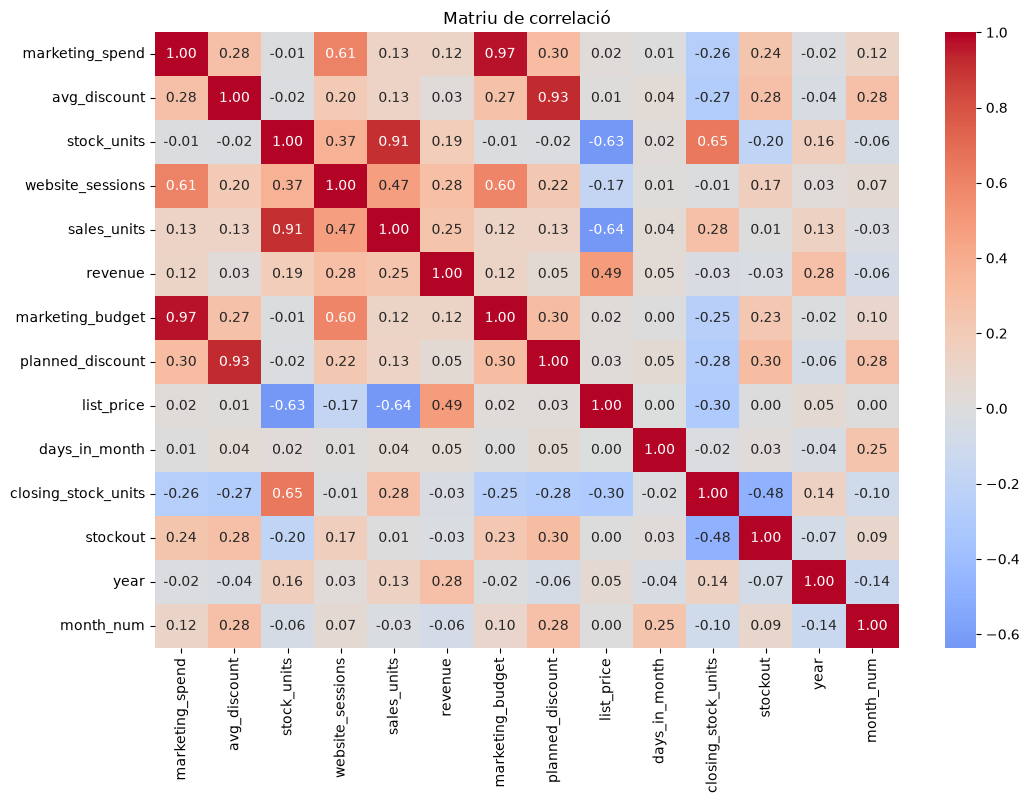

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Només columnes numèriques (la correlació no funciona amb text)
corr = df_model.select_dtypes(include="number").corr()

# Dibuix de la matriu
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriu de correlació")
plt.show()

In [18]:
# Correlació de cada variable amb sales_units, ordenada
print(corr["sales_units"].sort_values(ascending=False))

sales_units            1.000000
stock_units            0.909997
website_sessions       0.474238
closing_stock_units    0.280316
revenue                0.254055
year                   0.131190
planned_discount       0.127347
marketing_spend        0.127311
avg_discount           0.126189
marketing_budget       0.118384
days_in_month          0.041838
stockout               0.006511
month_num             -0.025465
list_price            -0.637588
Name: sales_units, dtype: float64


In [112]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 1188 entries, 0 to 1187
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   month                  1188 non-null   datetime64[us]
 1   marketing_spend        1188 non-null   float64       
 2   avg_discount           1188 non-null   float64       
 3   stock_units            1188 non-null   int64         
 4   website_sessions       1188 non-null   float64       
 5   sales_units            1188 non-null   int64         
 6   revenue                1188 non-null   float64       
 7   marketing_budget       1188 non-null   float64       
 8   planned_discount       1188 non-null   float64       
 9   list_price             1188 non-null   float64       
 10  days_in_month          1188 non-null   int64         
 11  closing_stock_units    1188 non-null   int64         
 12  stockout               1188 non-null   int64         
 13  year          

# Model polinominal

En este fitxer provarem el model de regressió polinomial ajustant el grau del polinomi (primer grau 2, i si no és molt lent podeu intentar a veure què passa amb grau 3).

Dividim les dades en un conjunt d'entrenament i un conjunt de test (per exemple, 80% per entrenar i 20% per test). Una vegada teniu les dades d'entrenament i les dades de test, podeu entrenar els diferents models que heu preparat.


In [96]:
# Dividim les dades en entrenament i test
from sklearn.model_selection import train_test_split

# X: deixar fora: revenue, closing_stock_units, stockout.

remov_cols = ["closing_stock_units", "month", "sales_units", "revenue", "stockout", ]

X = df_model.drop(columns=remov_cols)
y = df_model["sales_units"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [123]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def get_pred_poly(grau):

    polynomial_model = make_pipeline(RobustScaler(), PolynomialFeatures(degree=grau), LinearRegression())
    polynomial_model.fit(X_train, y_train)


    # Predim
    y_pred_polynomial = polynomial_model.predict(X_test)

    return y_pred_polynomial


def show_pred_polynomial(grau, X_train, X_test, y_train, y_test):
    
    polynomial_model = make_pipeline(RobustScaler(), PolynomialFeatures(degree=grau), LinearRegression())
    polynomial_model.fit(X_train, y_train)

    # Predim
    y_pred_polynomial = polynomial_model.predict(X_test)

    print("Polinomial  R²:", r2_score(y_test, y_pred_polynomial),
          "MSE:", mean_squared_error(y_test, y_pred_polynomial),
          "MAE:", mean_absolute_error(y_test, y_pred_polynomial))

    # Comprovació 1: Comparar amb el de train
    print("R² train:", polynomial_model.score(X_train, y_train))
    print("R² test :", r2_score(y_test, y_pred_polynomial))


In [124]:
show_pred_polynomial(3, X_train, X_test, y_train, y_test)

Polinomial  R²: -5.8132140425172425 MSE: 15784.734589752688 MAE: 74.10455639914287
R² train: 0.9956321817230948
R² test : -5.8132140425172425


## Avaluació amb les dades de test
Anem a calcular:

- Error quadràtic mitjà (MSE)
- Error absolut mitjà (MAE)
- R²

Per visualitzar els resultats de manera gràfica també podeu fer gràfics de dispersió entre les prediccions i els valors reals per veure com de bé s'ajusten les prediccions a la realitat.

In [136]:
# Comprovació 2: 
for grau in [2]:

    print(f"Grau {grau}:")
    show_pred_polynomial(grau, X_train, X_test, y_train, y_test)
    print("\n")


Grau 2:
Polinomial  R²: 0.9125446545975792 MSE: 202.61500769207152 MAE: 10.698564688699197
R² train: 0.9480094439716987
R² test : 0.9125446545975792




In [137]:
# El grau 2 és el millor de la comparació (R² 0,9125, MAE 10,7), però amb una millora modesta respecte a la regressió lineal.

# El grau 3 s’ha de descartar per sobreajust.

## Gràfic de prediccions

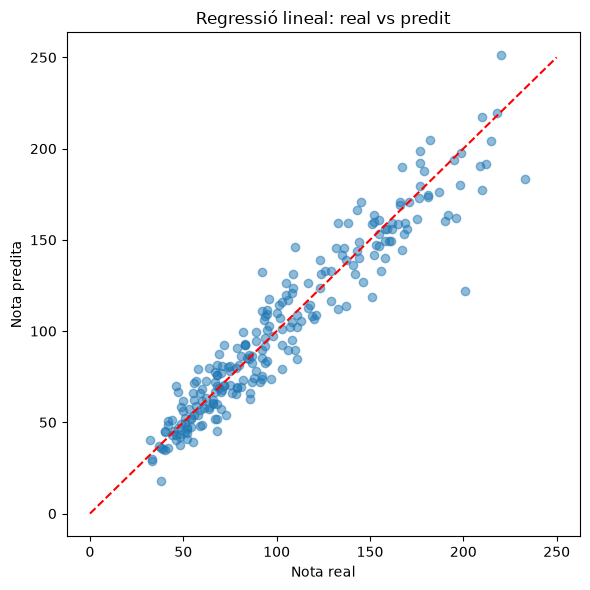

In [142]:
# Gràfic prediccions vs real (regressió lineal)

pred_poly = get_pred_poly(2)

def scatter(pred):

    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred, alpha=0.5)
    plt.plot([0, 250], [0, 250], "r--")
    plt.xlabel("Nota real")
    plt.ylabel("Nota predita")
    plt.title("Regressió lineal: real vs predit")
    plt.tight_layout()
    plt.savefig("regressio_lineal_prediccions.png", dpi=120)
    plt.show()
    plt.close()

scatter(pred_poly)

## Polinomi només a les numèriques, deixant passar les dummies.

In [143]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Columnes numèriques (les dummies són booleanes, així que queden fora)
num_cols = X_train.select_dtypes(include="number").columns.tolist()
print(num_cols)

def build_model(grau):
    pre = ColumnTransformer(
        [("num",
          make_pipeline(RobustScaler(),
                        PolynomialFeatures(degree=grau, include_bias=False)),
          num_cols)],
        remainder="passthrough"   # les dummies passen sense canvis
    )
    return make_pipeline(pre, LinearRegression())

def avalua(grau):
    model = build_model(grau).fit(X_train, y_train)
    pred = model.predict(X_test)


    print(f"Grau {grau}:")
    print("Polinomial  R²:", r2_score(y_test, pred)),
    print("  R² train:", model.score(X_train, y_train))
    print("  R² test :", r2_score(y_test, pred))
    print("  MAE     :", mean_absolute_error(y_test, pred))
    print("  MSE    :", mean_squared_error(y_test, pred))
    print()
    return model, pred

for grau in [1, 2, 3]:
    avalua(grau)

['marketing_spend', 'avg_discount', 'stock_units', 'website_sessions', 'marketing_budget', 'planned_discount', 'list_price', 'days_in_month', 'year', 'month_num']
Grau 1:
Polinomial  R²: 0.9028778713781669
  R² train: 0.9036810909368287
  R² test : 0.9028778713781669
  MAE     : 11.360659729227722
  MSE    : 225.01084121541138

Grau 2:
Polinomial  R²: 0.9243973327478483
  R² train: 0.9314977930207349
  R² test : 0.9243973327478483
  MAE     : 10.037837597335354
  MSE    : 175.1549311977427

Grau 3:
Polinomial  R²: 0.8293485089284099
  R² train: 0.9522529459726647
  R² test : 0.8293485089284099
  MAE     : 12.78410155121976
  MSE    : 395.3623762736474



Grau 2:
Polinomial  R²: 0.9243973327478483
  R² train: 0.9314977930207349
  R² test : 0.9243973327478483
  MAE     : 10.037837597335354
  MSE    : 175.1549311977427



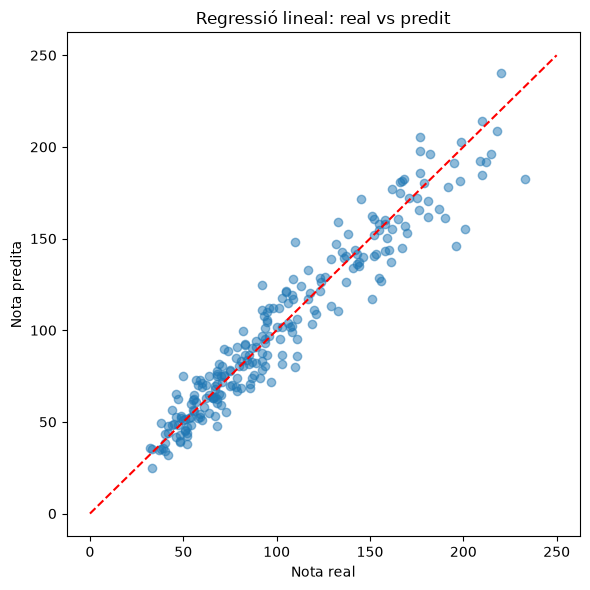

In [ ]:
model, pred = avalua(2)

scatter(pred)